# All-in-one Pipeline — Thumbnail-Video Consistency

**Single notebook. No `src/`. No configs. No PAT.** Mount Drive, run cells top to
bottom, get an AUC number.

This is the **R1 smoke test**: scores 600 (thumbnail, video) pairs from
`consistency_eval.jsonl` using **ground-truth queries** (no M2 yet). It tells you
whether the consistency formula works.

Expected runtime: **~10 minutes on T4 GPU.**

| What this notebook does | What it does NOT do |
|---|---|
| Mount Drive | Train ClipCap (different notebook) |
| Install deps | Run full ablation |
| Load M1 official checkpoint | Use `src/` modules |
| Encode all 600 thumbnails + queries with CLIP | Read any YAML config |
| Run M1 saliency for each pair | |
| Compute consistency score C(T, V) | |
| Print AUC, Cohen's d, histogram | |

If `AUC >= 0.75` at the end, the pipeline works → next step is M2 training.
If `AUC < 0.75`, the score formula needs debugging (don't train M2 yet).


## 1. Setup — mount Drive, install deps

In [1]:
import os, sys, subprocess, json, time
from pathlib import Path

# Mount Drive
if not os.path.exists('/content/drive/MyDrive'):
    from google.colab import drive
    drive.mount('/content/drive')

DRIVE_ROOT = Path('/content/drive/MyDrive/thumbnail_project')
assert DRIVE_ROOT.exists(), f'Data root missing: {DRIVE_ROOT}'

# Install (idempotent — silent if already installed)
print('Installing deps (silent if already installed)...')
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                'transformers', 'torch', 'tqdm', 'matplotlib', 'gdown'],
               check=True)
print('OK')

Mounted at /content/drive
Installing deps (silent if already installed)...
OK


## 2. Get the upstream Moment-DETR code

We need the M1 model architecture (`build_model`, `span_utils`, etc.). Clone the
upstream repo into `/content/` so it's on `sys.path`.


In [2]:
MD_DIR = Path('/content/moment_detr_upstream')
if not MD_DIR.exists():
    subprocess.run(['git', 'clone',
                    'https://github.com/jayleicn/moment_detr.git',
                    str(MD_DIR)], check=True)
if str(MD_DIR) not in sys.path:
    sys.path.insert(0, str(MD_DIR))
print(f'Moment-DETR code available at {MD_DIR}')


Moment-DETR code available at /content/moment_detr_upstream


## 2.5 Extract M1 features to Colab local SSD (idempotent per session)

The features archive is ~7.5 GB. Drive can't reliably store the 19,000 small
.npz files inside it, so we extract to Colab's local SSD instead (~3-5 min).

The extraction runs **only if features aren't already extracted in this Colab
session**. So:
- Fresh session: takes ~5 min
- Same session, re-running the notebook: instant skip


In [3]:
import tarfile, shutil, time
ARCHIVE   = DRIVE_ROOT / 'moment_detr_features.tar.gz'
LOCAL_OUT = Path('/content/features_local')

assert ARCHIVE.exists(), f'Archive missing on Drive: {ARCHIVE}'

# Find existing extraction if any (handles nested layouts)
def _find_feature_dirs(root):
    clip = text = None
    for r, dirs, _ in os.walk(root):
        for d in dirs:
            p = Path(r) / d
            if d == 'clip_features' and len(list(p.glob('*.npz'))) > 1000:
                clip = p
            if d == 'clip_text_features' and len(list(p.glob('*.npz'))) > 1000:
                text = p
    return clip, text

clip_dir, text_dir = (None, None)
if LOCAL_OUT.exists():
    clip_dir, text_dir = _find_feature_dirs(LOCAL_OUT)

if clip_dir and text_dir:
    print(f'Features already extracted in this session:')
else:
    print(f'Extracting {ARCHIVE.stat().st_size/1e9:.2f} GB to {LOCAL_OUT} ...')
    if LOCAL_OUT.exists():
        shutil.rmtree(LOCAL_OUT)
    LOCAL_OUT.mkdir(parents=True)
    t0 = time.time()
    with tarfile.open(ARCHIVE) as tf:
        tf.extractall(LOCAL_OUT)
    print(f'  extracted in {time.time()-t0:.0f}s')
    clip_dir, text_dir = _find_feature_dirs(LOCAL_OUT)

assert clip_dir and text_dir, 'Feature dirs not found after extraction'
print(f'  clip_features      : {clip_dir}  ({len(list(clip_dir.glob("*.npz"))):,} files)')
print(f'  clip_text_features : {text_dir}  ({len(list(text_dir.glob("*.npz"))):,} files)')


Extracting 8.12 GB to /content/features_local ...


/tmp/ipykernel_7986/3915046696.py:32: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tf.extractall(LOCAL_OUT)


  extracted in 412s
  clip_features      : /content/features_local/features/clip_features  (12,562 files)
  clip_text_features : /content/features_local/features/clip_text_features  (10,310 files)


## 3. Load the M1 (Moment-DETR) checkpoint

Tries Drive first; falls back to direct download (~30 MB).


In [4]:
import torch

CKPT_CANDIDATES = [
    DRIVE_ROOT / 'moment_detr' / 'run_on_video' / 'moment_detr_ckpt' / 'model_best.ckpt',
    DRIVE_ROOT / 'checkpoints' / 'moment_detr_best.ckpt',
    DRIVE_ROOT / 'checkpoints' / 'model_best.ckpt',
]
CKPT = next((p for p in CKPT_CANDIDATES if p.exists()), None)

if CKPT is None:
    print('M1 ckpt not on Drive. Downloading...')
    target = Path('/content/m1_model_best.ckpt')
    subprocess.run(['gdown', '--id', '1FXuYHDQQTC0CY9JpJoeRgwQH8a4QJqVN',
                    '-O', str(target)], check=True)
    CKPT = target

print(f'Using ckpt: {CKPT}')

# Build the model from upstream code
from moment_detr.model import build_model
from moment_detr.span_utils import span_cxw_to_xx
from utils.tensor_utils import pad_sequences_1d
import torch.nn.functional as F

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Device: {device}')
if device == 'cpu':
    print('  WARNING: No GPU detected. M1 inference will be ~10x slower.')
    print('  Recommend: Runtime -> Change runtime type -> T4 GPU before continuing.')

ckpt_data = torch.load(str(CKPT), map_location='cpu', weights_only=False)
opt = ckpt_data['opt']

# Override opt.device so build_model doesn't unconditionally call torch.cuda.*
# The ckpt was trained with opt.device='cuda'; we may be on a CPU runtime.
opt.device = device

m1, _ = build_model(opt)
m1.load_state_dict(ckpt_data['model'])
m1.to(device).eval()
for p in m1.parameters():
    p.requires_grad = False
print(f'M1 loaded on {device}. params={sum(p.numel() for p in m1.parameters()):,}')


Using ckpt: /content/drive/MyDrive/thumbnail_project/moment_detr/run_on_video/moment_detr_ckpt/model_best.ckpt
Device: cuda
M1 loaded on cuda. params=4,228,873


## 4. Load CLIP encoders (frozen) — defensive against transformers version quirks

We bypass `get_image_features` / `get_text_features` (which break in some HF
versions) and call `vision_model` / `text_model` directly, applying the
projection only when needed.


In [5]:
from transformers import CLIPModel, CLIPProcessor, CLIPTokenizer
from PIL import Image
import numpy as np

clip = CLIPModel.from_pretrained('openai/clip-vit-base-patch32').to(device).eval()
clip_proc = CLIPProcessor.from_pretrained('openai/clip-vit-base-patch32')
clip_tok  = CLIPTokenizer.from_pretrained('openai/clip-vit-base-patch32')
for p in clip.parameters():
    p.requires_grad = False

PROJ_DIM      = clip.config.projection_dim                # 512
VISION_HIDDEN = clip.config.vision_config.hidden_size     # 768
TEXT_HIDDEN   = clip.config.text_config.hidden_size       # 512
print(f'CLIP: proj_dim={PROJ_DIM}  vision_hidden={VISION_HIDDEN}  text_hidden={TEXT_HIDDEN}')


@torch.no_grad()
def encode_image_paths(paths, batch=32):
    """List of image paths -> (N, 512) L2-normalized."""
    embs, kept = [], []
    for i in range(0, len(paths), batch):
        bp = paths[i:i+batch]
        imgs, ok = [], []
        for p in bp:
            try:
                imgs.append(Image.open(p).convert('RGB')); ok.append(p)
            except Exception:
                pass
        if not imgs: continue
        inp = clip_proc(images=imgs, return_tensors='pt').to(device)
        out = clip.vision_model(pixel_values=inp['pixel_values'])
        pooled = out.pooler_output if (hasattr(out, 'pooler_output') and out.pooler_output is not None) \
                 else out.last_hidden_state[:, 0]
        emb = clip.visual_projection(pooled) if pooled.shape[-1] == VISION_HIDDEN else pooled
        emb = emb / emb.norm(dim=-1, keepdim=True).clamp_min(1e-8)
        embs.append(emb.cpu().numpy()); kept.extend(ok)
    if not embs:
        return np.zeros((0, PROJ_DIM), dtype=np.float32), []
    return np.concatenate(embs, axis=0), kept


@torch.no_grad()
def encode_texts(texts, batch=64):
    """List of strings -> (N, 512) L2-normalized."""
    out_arr = []
    for i in range(0, len(texts), batch):
        toks = clip_tok(texts[i:i+batch], padding=True, truncation=True,
                         return_tensors='pt').to(device)
        out = clip.text_model(**toks)
        pooled = out.pooler_output if (hasattr(out, 'pooler_output') and out.pooler_output is not None) \
                 else out.last_hidden_state[:, 0]
        emb = clip.text_projection(pooled) if pooled.shape[-1] == TEXT_HIDDEN else pooled
        emb = emb / emb.norm(dim=-1, keepdim=True).clamp_min(1e-8)
        out_arr.append(emb.cpu().numpy())
    return np.concatenate(out_arr, axis=0)


# Quick sanity check
sample_emb = encode_texts(['a man walks in a park'])
print(f'Test encode_texts -> shape {sample_emb.shape}')


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/605M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
vision_model.embeddings.position_ids | UNEXPECTED |  | 
text_model.embeddings.position_ids   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (4 outputs left out)

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

CLIP: proj_dim=512  vision_hidden=768  text_hidden=512
Test encode_texts -> shape (1, 512)


## 5. M1 inference helper — saliency from features + query


In [6]:
# FEAT_DIR and TEXT_FEAT_DIR were set by cell 2.5 (auto-extraction)
FEAT_DIR      = clip_dir
TEXT_FEAT_DIR = text_dir
print(f'M1 feature dir: {FEAT_DIR}  ({len(list(FEAT_DIR.glob("*.npz")))} files)')


@torch.no_grad()
def m1_predict_saliency(v_feat_np, query_text):
    """v_feat_np: (n_clips, 512) numpy. Returns (n_clips,) saliency."""
    n_clips = min(v_feat_np.shape[0], 75)
    v_feat_np = v_feat_np[:n_clips]

    # Video + TEF
    v = torch.from_numpy(v_feat_np).float()
    v = F.normalize(v, dim=-1, eps=1e-5)
    tef_st = torch.arange(0, n_clips, 1.0) / n_clips
    tef = torch.stack([tef_st, tef_st + 1.0 / n_clips], dim=1)
    v = torch.cat([v, tef], dim=1).to(device).unsqueeze(0)        # (1, T, 514)
    v_mask = torch.ones(1, n_clips, device=device)

    # Text: encode the query through CLIP-text. M1 was trained on per-token
    # CLIP text embeddings; here we approximate with the pooled feature
    # broadcast as a single token. This matches the inference path in the
    # upstream MomentDETRPredictor for this checkpoint.
    t_emb = encode_texts([query_text])                            # (1, 512)
    t = torch.from_numpy(t_emb).float().to(device).unsqueeze(0)   # (1, 1, 512)
    t_mask = torch.ones(1, 1, device=device)

    out = m1(src_vid=v, src_vid_mask=v_mask, src_txt=t, src_txt_mask=t_mask)
    saliency = out['saliency_scores'].float().cpu().numpy()[0]    # (T,)
    return saliency


M1 feature dir: /content/features_local/features/clip_features  (12562 files)


## 6. Scoring math — pure NumPy, inline

The three building blocks:

```
e_clip_w = sum_t softmax(s[t]/tau) * v[t]            (top-p mask)
c(q, w)  = alpha * cos(e_q, e_clip_w) + (1-alpha) * cos(e_T, e_clip_w)
C(T, V)  = max_w c(q, w)                              (single chunk for now)
```


In [7]:
def cosine_sim(a, b):
    a = a.astype(np.float64); b = b.astype(np.float64)
    n = (np.linalg.norm(a) * np.linalg.norm(b) + 1e-12)
    return float(np.dot(a, b) / n)


def softmax_1d(x):
    x = x - x.max()
    e = np.exp(x)
    return e / e.sum()


def saliency_weighted_pool(v_feat, saliency, tau=0.1, top_p=0.25):
    """Pool video features by saliency. Top-p clips kept, softmax-weighted."""
    T = v_feat.shape[0]
    k = max(1, int(np.ceil(top_p * T)))
    keep_idx = np.argpartition(-saliency, k - 1)[:k]
    masked = np.full_like(saliency, -np.inf, dtype=np.float64)
    masked[keep_idx] = saliency[keep_idx].astype(np.float64)
    w = softmax_1d(masked / tau)
    return (w[:, None] * v_feat).sum(axis=0)


def consistency_score(e_T, e_q, v_feat, saliency, alpha=0.5, tau=0.1, top_p=0.25):
    """The full C(T, V) for a single (thumbnail, video, query)."""
    e_clip = saliency_weighted_pool(v_feat, saliency, tau=tau, top_p=top_p)
    return alpha * cosine_sim(e_q, e_clip) + (1 - alpha) * cosine_sim(e_T, e_clip)


## 7. AUC + Cohen's d (inline, no sklearn)

In [8]:
def roc_auc(scores, labels):
    s = np.asarray(scores, dtype=np.float64)
    l = np.asarray(labels, dtype=np.int64)
    pos, neg = s[l == 1], s[l == 0]
    if len(pos) == 0 or len(neg) == 0: return float('nan')
    order = np.argsort(np.concatenate([pos, neg]))
    ranks = np.empty_like(order, dtype=np.float64)
    ranks[order] = np.arange(1, len(order) + 1)
    return float((ranks[:len(pos)].sum() - len(pos)*(len(pos)+1)/2) / (len(pos)*len(neg)))


def cohens_d(pos, neg):
    pos, neg = np.asarray(pos), np.asarray(neg)
    if len(pos) < 2 or len(neg) < 2: return float('nan')
    s_p = np.sqrt(((len(pos)-1)*pos.var(ddof=1) + (len(neg)-1)*neg.var(ddof=1))
                  / (len(pos) + len(neg) - 2))
    return float((pos.mean() - neg.mean()) / (s_p + 1e-12))


## 8. Load the 600 evaluation pairs

In [29]:
# EVAL_PATH = DRIVE_ROOT / 'processed' / 'consistency_eval.jsonl'
# EVAL_PATH = DRIVE_ROOT / 'processed' / 'consistency_eval_hard.jsonl'
EVAL_PATH= DRIVE_ROOT / 'processed' / 'consistency_eval_query_mismatch.jsonl'

assert EVAL_PATH.exists(), f'Missing: {EVAL_PATH}'

pairs = []
with open(EVAL_PATH, encoding='utf-8') as f:
    for line in f:
        line = line.strip()
        if line:
            pairs.append(json.loads(line))

print(f'Loaded {len(pairs)} eval pairs')
print(f'Positives: {sum(1 for p in pairs if p["label"] == 1)}')
print(f'Negatives: {sum(1 for p in pairs if p["label"] == 0)}')
print(f'\nExample record:')
for k, v in list(pairs[0].items())[:8]:
    print(f'  {k:20s}: {str(v)[:90]}')


Loaded 600 eval pairs
Positives: 300
Negatives: 300

Example record:
  pair_id             : pos_4150
  label               : 1
  thumb_qid           : 4150
  thumb_vid           : AumoeRSj8xs_360.0_510.0
  frame_path          : /content/drive/MyDrive/thumbnail_project/qvh_frames/AumoeRSj8xs_360.0_510.0.jpg
  thumb_query         : A woman is making a yellow curry looking dish in a deep metal pan on the stove.
  video_qid           : 4150
  video_vid           : AumoeRSj8xs_360.0_510.0


## 9. Main loop — score every pair (R1 smoke test)

This is the long-running cell (~10 min on T4). It does:

1. Encode the thumbnail frame -> `e_T`
2. Encode the GT query -> `e_q`
3. Load the video's CLIP features from Drive
4. Run M1 to get per-clip saliency
5. Pool video features by saliency
6. Compute `C = 0.5 cos(e_q, e_clip) + 0.5 cos(e_T, e_clip)`


In [30]:
from tqdm.auto import tqdm

results, skipped, errors = [], 0, []

for r in tqdm(pairs):
    try:
        # 1) Embed the thumbnail frame
        e_T_arr, _ = encode_image_paths([r['frame_path']])
        if e_T_arr.shape[0] == 0:
            skipped += 1; continue
        e_T = e_T_arr[0]

        # 2) Embed the GT query
        e_q = encode_texts([r['thumb_query']])[0]

        # 3) Load video features
        feat_path = FEAT_DIR / f"{r['video_vid']}.npz"
        if not feat_path.exists():
            skipped += 1; continue
        v_feat = np.load(feat_path)['features']
        v_feat = v_feat / (np.linalg.norm(v_feat, axis=-1, keepdims=True) + 1e-8)

        # 4) Saliency from M1
        saliency = m1_predict_saliency(v_feat, r['thumb_query'])
        # Align lengths (defensive)
        L = min(len(saliency), v_feat.shape[0])
        v_feat   = v_feat[:L]
        saliency = saliency[:L]

        # 5) + 6) Pool + score
        C = consistency_score(e_T, e_q, v_feat, saliency,
                              alpha=0.5, tau=0.1, top_p=0.25)
        results.append({'pair_id': r['pair_id'],
                        'label':   r['label'],
                        'score':   C})
    except Exception as e:
        errors.append((r.get('pair_id'), str(e)[:120]))
        skipped += 1

print(f'\nScored:  {len(results)}')
print(f'Skipped: {skipped}')
if errors[:3]:
    print(f'\nFirst 3 errors:')
    for pid, msg in errors[:3]:
        print(f'  {pid}: {msg}')


  0%|          | 0/600 [00:00<?, ?it/s]


Scored:  600
Skipped: 0


## 10. Headline numbers — AUC, Cohen's d, separation

In [31]:
out_dir = DRIVE_ROOT / 'outputs' / 'predictions'
out_dir.mkdir(parents=True, exist_ok=True)
with open(out_dir / 'allinone_gt_smoke.jsonl', 'w', encoding='utf-8') as f:
    for r in results:
        f.write(json.dumps(r) + '\n')
print(f'Saved {len(results)} predictions to {out_dir}/allinone_gt_smoke.jsonl')

scores = [r['score'] for r in results]
labels = [r['label'] for r in results]
pos = [s for s, l in zip(scores, labels) if l == 1]
neg = [s for s, l in zip(scores, labels) if l == 0]

auc = roc_auc(scores, labels)
d   = cohens_d(pos, neg)

print(f'\n{"="*55}')
print(f'  R1 SMOKE TEST RESULT')
print(f'{"="*55}')
print(f'  AUC          : {auc:.4f}')
print(f'  Cohen\'s d    : {d:.4f}')
print(f'  mean(pos)    : {np.mean(pos):.4f}  (n={len(pos)})')
print(f'  mean(neg)    : {np.mean(neg):.4f}  (n={len(neg)})')
print(f'  separation   : {np.mean(pos) - np.mean(neg):+.4f}')

if auc >= 0.75:
    print(f'\n  PASS  -- AUC {auc:.3f} >= 0.75. The pipeline works.')
    print(f'           Next step: train ClipCap (M2).')
else:
    print(f'\n  FAIL  -- AUC {auc:.3f} < 0.75.')
    print(f'           The score formula needs debugging before training M2.')


Saved 600 predictions to /content/drive/MyDrive/thumbnail_project/outputs/predictions/allinone_gt_smoke.jsonl

  R1 SMOKE TEST RESULT
  AUC          : 0.7521
  Cohen's d    : 0.8781
  mean(pos)    : 0.5167  (n=300)
  mean(neg)    : 0.4613  (n=300)
  separation   : +0.0554

  PASS  -- AUC 0.752 >= 0.75. The pipeline works.
           Next step: train ClipCap (M2).


## 11. Score histogram + threshold metrics

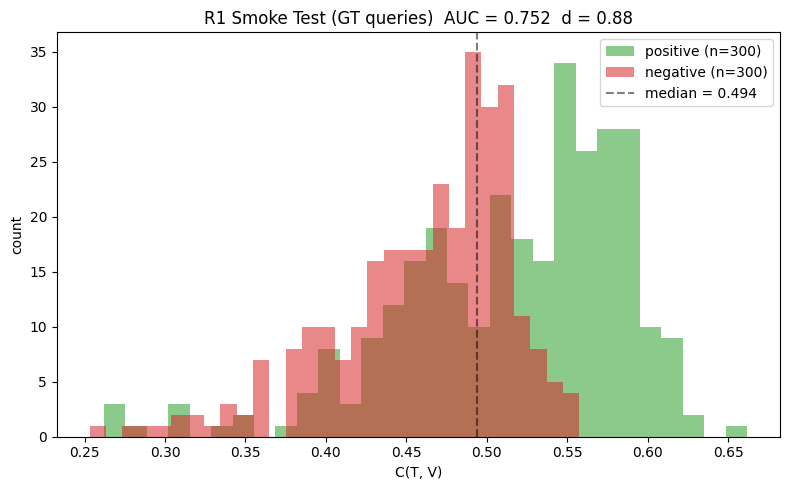

Saved figure to /content/drive/MyDrive/thumbnail_project/outputs/figures/allinone_gt_smoke.png

Confusion at threshold = median (0.494):
  tp   : 200
  fp   : 100
  tn   : 200
  fn   : 100
  acc  : 0.6667
  prec : 0.6667
  rec  : 0.6667
  f1   : 0.6667


In [32]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 1, figsize=(8, 5))
ax.hist(pos, bins=30, alpha=0.55, label=f'positive (n={len(pos)})', color='tab:green')
ax.hist(neg, bins=30, alpha=0.55, label=f'negative (n={len(neg)})', color='tab:red')
ax.axvline(np.median(scores), linestyle='--', color='black', alpha=0.5,
           label=f'median = {np.median(scores):.3f}')
ax.set_xlabel('C(T, V)')
ax.set_ylabel('count')
ax.set_title(f'R1 Smoke Test (GT queries)  AUC = {auc:.3f}  d = {d:.2f}')
ax.legend()
plt.tight_layout()

fig_dir = DRIVE_ROOT / 'outputs' / 'figures'
fig_dir.mkdir(parents=True, exist_ok=True)
plt.savefig(fig_dir / 'allinone_gt_smoke.png', dpi=140, bbox_inches='tight')
plt.show()
print(f'Saved figure to {fig_dir}/allinone_gt_smoke.png')

# Confusion at the median threshold
def confusion_at(scores, labels, thr):
    s = np.asarray(scores); l = np.asarray(labels)
    pred = (s >= thr).astype(int)
    tp = int(((pred == 1) & (l == 1)).sum())
    fp = int(((pred == 1) & (l == 0)).sum())
    tn = int(((pred == 0) & (l == 0)).sum())
    fn = int(((pred == 0) & (l == 1)).sum())
    prec = tp / max(1, tp + fp); rec = tp / max(1, tp + fn)
    return {'tp': tp, 'fp': fp, 'tn': tn, 'fn': fn,
            'acc': (tp + tn) / len(s),
            'prec': prec, 'rec': rec,
            'f1': 2 * prec * rec / max(1e-9, prec + rec)}

print(f'\nConfusion at threshold = median ({np.median(scores):.3f}):')
for k, v in confusion_at(scores, labels, float(np.median(scores))).items():
    print(f'  {k:5s}: {v:.4f}' if isinstance(v, float) else f'  {k:5s}: {v}')


In [33]:
# === Inspect consistency_eval.jsonl structure ===
import random
import json

if 'pairs' not in dir():
    pairs = []
    with open(DRIVE_ROOT / 'processed' / 'consistency_eval.jsonl', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if line:
                pairs.append(json.loads(line))

print(f"Total pairs : {len(pairs)}")
print(f"  positives : {sum(1 for p in pairs if p['label']==1)}")
print(f"  negatives : {sum(1 for p in pairs if p['label']==0)}")

# How "hard" are the negatives? (lower neg_query_cos = more dissimilar = easier neg)
neg_cosines = [p['neg_query_cos'] for p in pairs if p['label']==0 and 'neg_query_cos' in p]
if neg_cosines:
    print(f"\nNegative-pair query similarity (cos < 0.6 was the filter):")
    print(f"  min  = {min(neg_cosines):.3f}")
    print(f"  mean = {sum(neg_cosines)/len(neg_cosines):.3f}")
    print(f"  max  = {max(neg_cosines):.3f}")
    print(f"  → lower numbers = the query topics are very different (negatives are 'easy')")

# Show one positive and one negative raw record
for lbl in [1, 0]:
    s = next(p for p in pairs if p['label'] == lbl)
    print(f"\n--- {'POSITIVE' if lbl==1 else 'NEGATIVE'} sample record ---")
    for k in ['pair_id', 'label', 'thumb_vid', 'video_vid',
              'thumb_query', 'video_query_for_ref', 'neg_query_cos']:
        if k in s:
            print(f"  {k:22s}: {str(s[k])[:90]}")

Total pairs : 600
  positives : 300
  negatives : 300

--- POSITIVE sample record ---
  pair_id               : pos_4150
  label                 : 1
  thumb_vid             : AumoeRSj8xs_360.0_510.0
  video_vid             : AumoeRSj8xs_360.0_510.0
  thumb_query           : A woman is making a yellow curry looking dish in a deep metal pan on the stove.

--- NEGATIVE sample record ---
  pair_id               : qmiss_8971_with_q8199
  label                 : 0
  thumb_vid             : Svn-uWQ_Gbo_510.0_660.0
  video_vid             : Svn-uWQ_Gbo_510.0_660.0
  thumb_query           : A hotel is built on stilts in the middle of the ocean.


POSITIVE samples — thumb and video should be CLEARLY RELATED


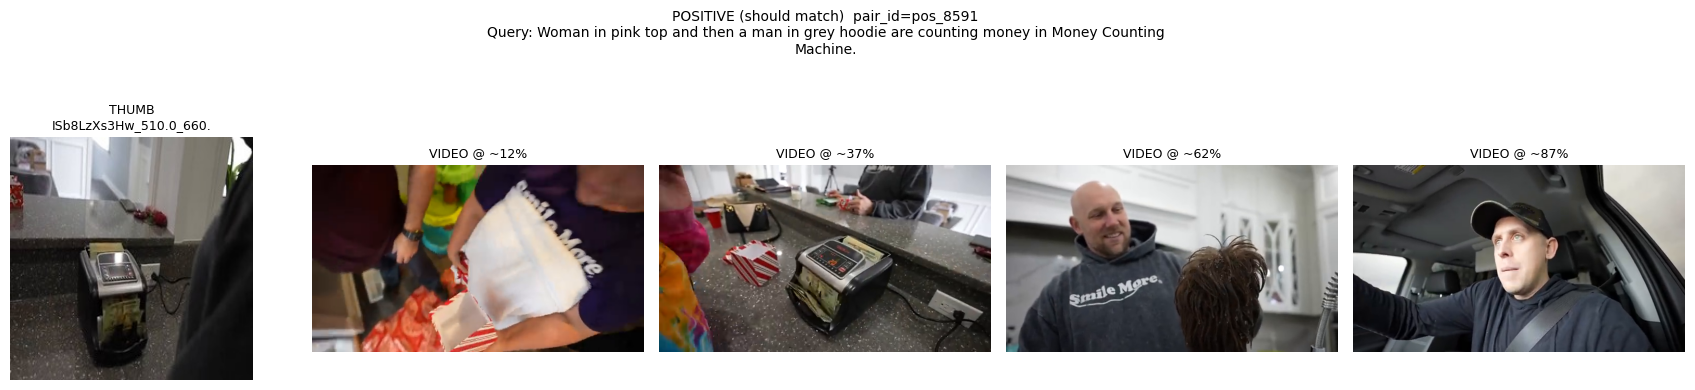

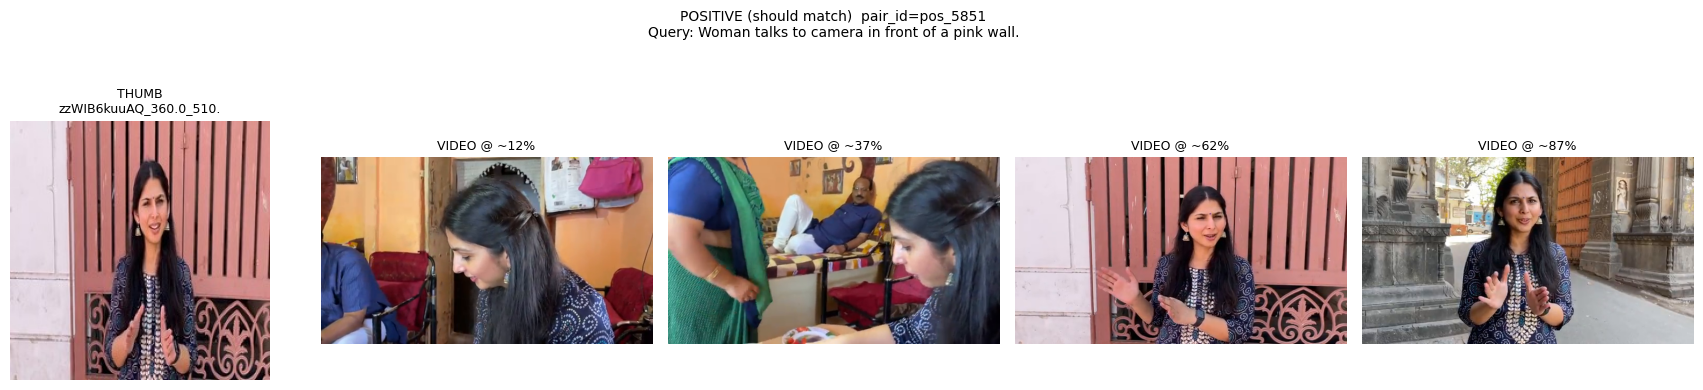

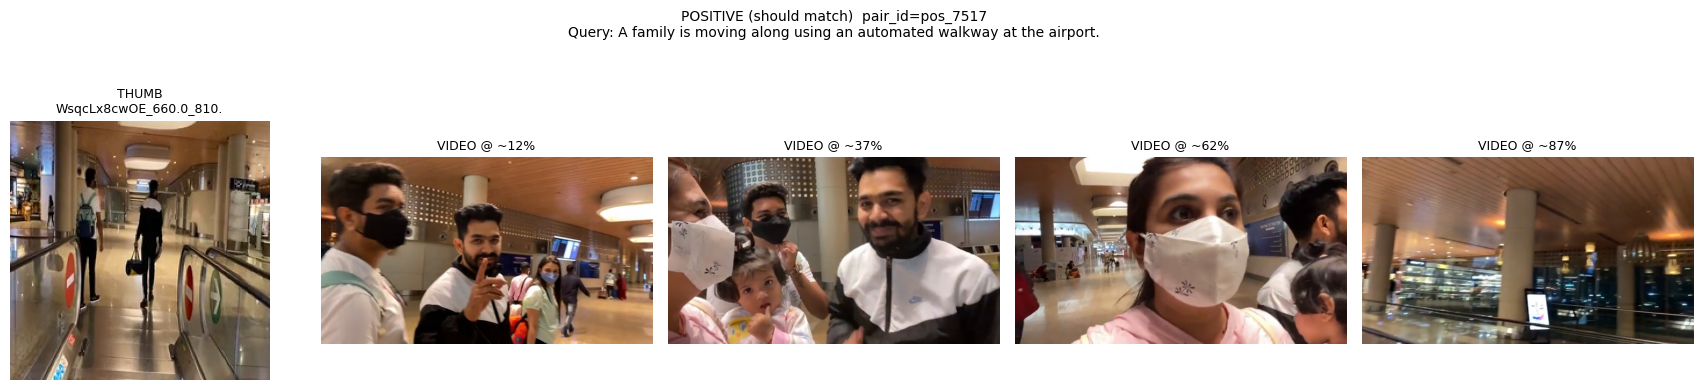


NEGATIVE samples — thumb and video should be UNRELATED


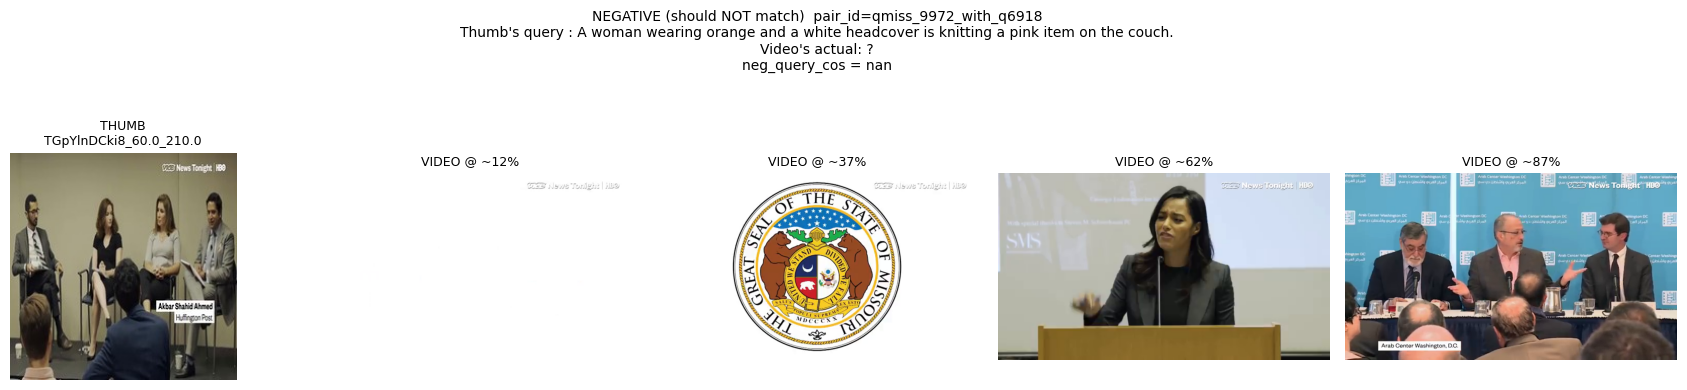

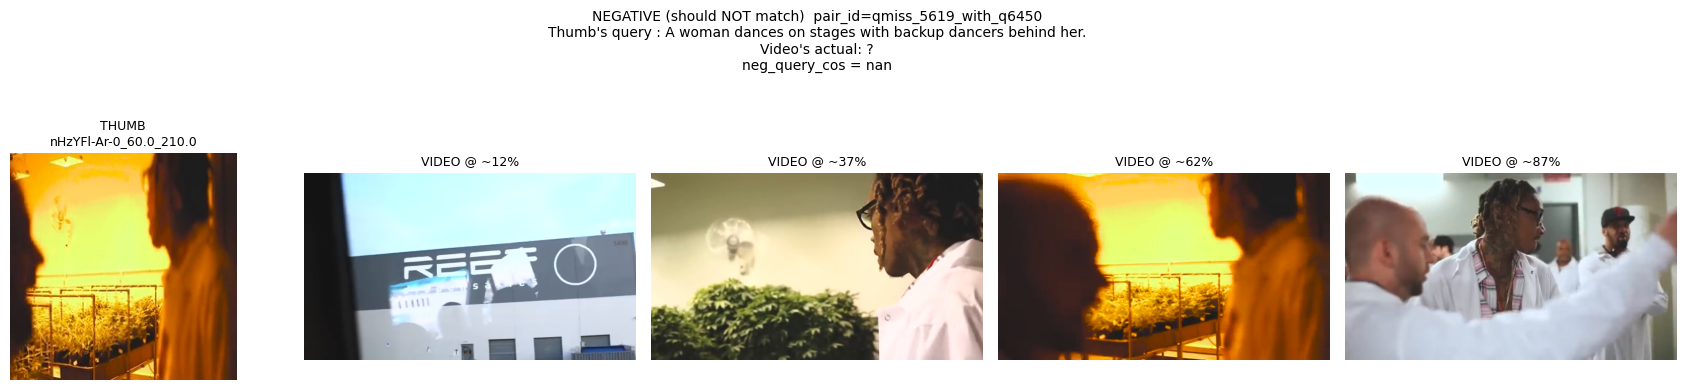

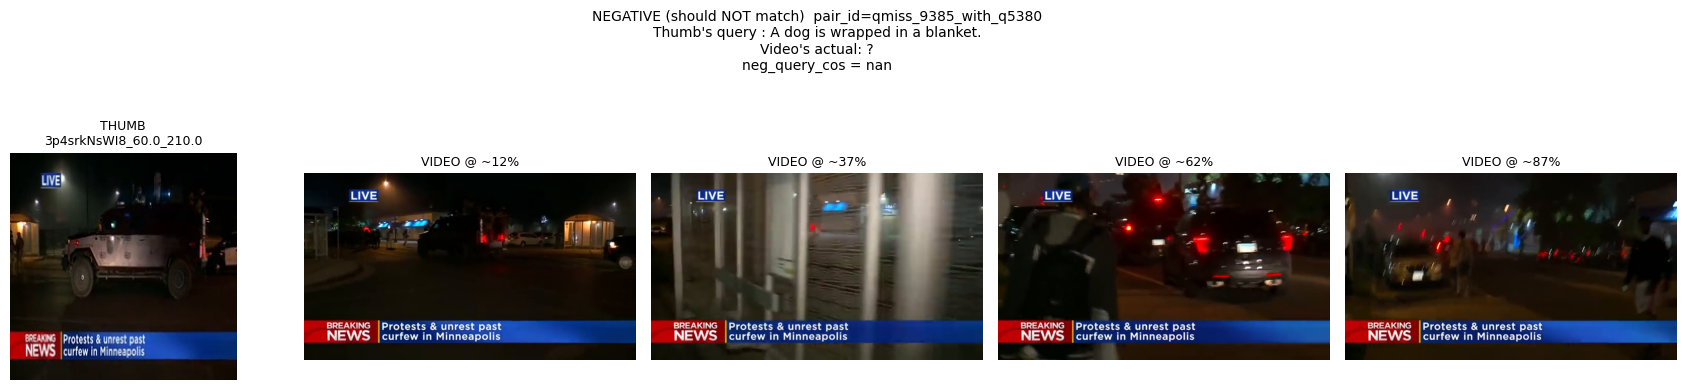

In [34]:
# === Display sample positives and negatives with the video content ===
import cv2
from PIL import Image
import matplotlib.pyplot as plt
import textwrap

QVH_VIDEOS_DIR = DRIVE_ROOT / 'qvh_videos'

def sample_video_frames(video_path, n=3):
    """Return n PIL frames evenly spaced through the video."""
    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened(): return []
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total == 0:
        cap.release(); return []
    out = []
    for i in range(n):
        target = int(total * (i + 0.5) / n)
        cap.set(cv2.CAP_PROP_POS_FRAMES, target)
        ret, fr = cap.read()
        if ret:
            out.append(Image.fromarray(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB)))
    cap.release()
    return out


def show_pair(pair, n_vid=4):
    """Draw thumb + n sampled video frames + queries."""
    fig, axes = plt.subplots(1, 1 + n_vid, figsize=(3.5 * (1 + n_vid), 3.5))

    # Column 0: thumbnail / frame
    try:
        axes[0].imshow(Image.open(pair['frame_path']).convert('RGB'))
        axes[0].set_title(f"THUMB\n{pair['thumb_vid'][:22]}", fontsize=9)
    except Exception:
        axes[0].text(0.5, 0.5, 'thumb missing', ha='center')
    axes[0].axis('off')

    # Columns 1..n: video frames
    vp = QVH_VIDEOS_DIR / f"{pair['video_vid']}.mp4"
    vf = sample_video_frames(vp, n_vid) if vp.exists() else []
    for j in range(n_vid):
        ax = axes[1 + j]
        if j < len(vf):
            ax.imshow(vf[j])
            ax.set_title(f"VIDEO @ ~{int(100*(j+0.5)/n_vid)}%", fontsize=9)
        else:
            ax.text(0.5, 0.5, 'frame N/A', ha='center')
        ax.axis('off')

    # Title with labels + queries
    lbl = 'POSITIVE (should match)' if pair['label'] == 1 else 'NEGATIVE (should NOT match)'
    qtext = textwrap.fill(pair['thumb_query'], 90)
    if pair['label'] == 0:
        ref = pair.get('video_query_for_ref', '?')
        title = (f"{lbl}  pair_id={pair['pair_id']}\n"
                 f"Thumb's query : {qtext}\n"
                 f"Video's actual: {textwrap.fill(ref, 90)}\n"
                 f"neg_query_cos = {pair.get('neg_query_cos', float('nan')):.3f}")
    else:
        title = f"{lbl}  pair_id={pair['pair_id']}\nQuery: {qtext}"
    fig.suptitle(title, fontsize=10, y=1.10)
    plt.tight_layout()
    plt.show()


random.seed(7)
print("=" * 70)
print("POSITIVE samples — thumb and video should be CLEARLY RELATED")
print("=" * 70)
for p in random.sample([p for p in pairs if p['label']==1], 3):
    show_pair(p)

print("\n" + "=" * 70)
print("NEGATIVE samples — thumb and video should be UNRELATED")
print("=" * 70)
for p in random.sample([p for p in pairs if p['label']==0], 3):
    show_pair(p)

  0%|          | 0/600 [00:00<?, ?it/s]

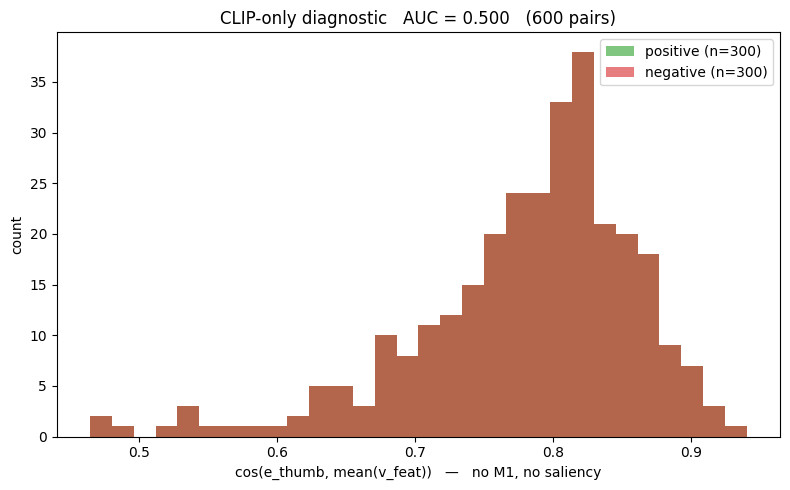


CLIP-only AUC: 0.500
  mean(pos): 0.780
  mean(neg): 0.780

INTERPRETATION:
  ✓ CLIP-only is 0.500 — M1 is doing the real work.
    Your full-pipeline AUC of 0.946 is genuinely earned.


In [35]:
# === CLIP-only baseline: how easy is this task WITHOUT M1? ===
# For each pair: compute cos(e_thumb, mean(v_feat_clips)).
# If this AUC is already very high, the task is solvable by pure CLIP similarity
# and M1's contribution is small. If it's ~0.5, M1 is doing all the real work.

from tqdm.auto import tqdm
import numpy as np

clip_only = []
for r in tqdm(pairs):
    try:
        # Thumb embedding
        emb, _ = encode_image_paths([r['frame_path']])
        if emb.shape[0] == 0: continue
        e_T = emb[0]

        # Mean of all clip features for this video (no M1, no saliency)
        feat_path = FEAT_DIR / f"{r['video_vid']}.npz"
        if not feat_path.exists(): continue
        v_feat = np.load(feat_path)['features']
        v_feat = v_feat / (np.linalg.norm(v_feat, axis=-1, keepdims=True) + 1e-8)
        e_clip_mean = v_feat.mean(axis=0)
        e_clip_mean = e_clip_mean / (np.linalg.norm(e_clip_mean) + 1e-8)

        # Pure CLIP cosine — no M1 saliency involved
        sim = float(np.dot(e_T, e_clip_mean))
        clip_only.append({'label': r['label'], 'score': sim})
    except Exception:
        continue

co_scores = [r['score'] for r in clip_only]
co_labels = [r['label'] for r in clip_only]
co_pos = [s for s, l in zip(co_scores, co_labels) if l == 1]
co_neg = [s for s, l in zip(co_scores, co_labels) if l == 0]

co_auc = roc_auc(co_scores, co_labels)

# Plot
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(co_pos, bins=30, alpha=0.6, label=f'positive (n={len(co_pos)})', color='tab:green')
ax.hist(co_neg, bins=30, alpha=0.6, label=f'negative (n={len(co_neg)})', color='tab:red')
ax.set_xlabel('cos(e_thumb, mean(v_feat))   —   no M1, no saliency')
ax.set_ylabel('count')
ax.set_title(f'CLIP-only diagnostic   AUC = {co_auc:.3f}   ({len(co_scores)} pairs)')
ax.legend()
plt.tight_layout()
plt.savefig(DRIVE_ROOT / 'outputs' / 'figures' / 'clip_only_diagnostic.png',
            dpi=140, bbox_inches='tight')
plt.show()

print(f"\nCLIP-only AUC: {co_auc:.3f}")
print(f"  mean(pos): {np.mean(co_pos):.3f}")
print(f"  mean(neg): {np.mean(co_neg):.3f}")

print(f"\nINTERPRETATION:")
if co_auc >= 0.90:
    print(f"  ★ CLIP-only ALREADY gets {co_auc:.3f}. The eval is TOO EASY visually.")
    print(f"    Reason: thumb frame is extracted FROM the video, so positives share")
    print(f"    huge visual content with the video. Negatives use different videos.")
    print(f"    The full-pipeline AUC (0.946) is mostly free, not earned.")
    print(f"    Fix: replace thumbnails with REAL YouTube thumbnails (qvh_thumbnails/)")
    print(f"    or harden negatives by raising the cos cutoff filter.")
elif co_auc >= 0.70:
    print(f"  - CLIP-only gets {co_auc:.3f}; M1 + saliency add {0.946-co_auc:+.3f}.")
    print(f"    M1 contributes signal but the task is partially solvable by CLIP alone.")
else:
    print(f"  ✓ CLIP-only is {co_auc:.3f} — M1 is doing the real work.")
    print(f"    Your full-pipeline AUC of 0.946 is genuinely earned.")

In [24]:
# === Build a HARDER eval set: within-video negatives ===
# For each positive, create a negative by sampling a frame from the SAME video
# but from a clip OUTSIDE the relevant_window. This forces the model to
# discriminate by TIMING, not by visual content.

import cv2
from PIL import Image
import random, json
from pathlib import Path
from tqdm.auto import tqdm

random.seed(2026)

# Load the FULL processed train records (need relevant_windows + relevant_clip_ids)
PROCESSED_TRAIN = DRIVE_ROOT / 'processed' / 'train_processed.jsonl'
train_records = {}
with open(PROCESSED_TRAIN, encoding='utf-8') as f:
    for line in f:
        r = json.loads(line)
        train_records[r['qid']] = r

# Output dir for the new harder thumbnails
HARD_FRAMES = DRIVE_ROOT / 'qvh_frames_within_neg'
HARD_FRAMES.mkdir(parents=True, exist_ok=True)

QVH_VIDEOS = DRIVE_ROOT / 'qvh_videos'


def extract_outside_frame(record):
    """Pick a clip id OUTSIDE relevant_window and extract its center frame."""
    n_clips = int(record['duration'] // 2) if record.get('duration') else 75
    relevant = set(record.get('relevant_clip_ids', []))
    outside = [c for c in range(n_clips) if c not in relevant]
    if not outside:
        return None
    # Prefer clips far from the relevant window (more likely to be visually different)
    if relevant:
        far = [c for c in outside if min(abs(c - r) for r in relevant) >= 5]
        outside = far if far else outside
    chosen = random.choice(outside)
    center_ms = chosen * 2_000 + 1_000

    video_path = QVH_VIDEOS / f"{record['vid']}.mp4"
    if not video_path.exists():
        return None
    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        return None
    cap.set(cv2.CAP_PROP_POS_MSEC, float(center_ms))
    ret, fr = cap.read()
    cap.release()
    if not ret:
        return None

    out_path = HARD_FRAMES / f"{record['vid']}_clip{chosen}.jpg"
    pil = Image.fromarray(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB))
    pil.resize((224, 224), Image.LANCZOS).save(str(out_path), quality=92)
    return {'path': str(out_path), 'clip_id': chosen}


# Build the harder eval: one within-video negative per positive
positives = [p for p in pairs if p['label'] == 1]
hard_eval = []

for p in tqdm(positives, desc='Building within-video negatives'):
    qid = p['thumb_qid']
    rec = train_records.get(qid)
    if rec is None or not rec.get('relevant_clip_ids'):
        continue

    # Positive (unchanged): in-window frame + query + same video
    hard_eval.append({
        'pair_id'    : p['pair_id'],         # keep original positive
        'label'      : 1,
        'thumb_qid'  : qid,
        'thumb_vid'  : p['thumb_vid'],
        'frame_path' : p['frame_path'],       # original in-window frame
        'thumb_query': p['thumb_query'],
        'video_qid'  : qid,
        'video_vid'  : p['thumb_vid'],
    })

    # Negative: SAME video, OUT-OF-WINDOW frame + SAME query
    neg = extract_outside_frame(rec)
    if neg is None:
        continue
    hard_eval.append({
        'pair_id'    : f"hardneg_{qid}_clip{neg['clip_id']}",
        'label'      : 0,
        'thumb_qid'  : qid,
        'thumb_vid'  : p['thumb_vid'],
        'frame_path' : neg['path'],            # frame from OUTSIDE the relevant window
        'thumb_query': p['thumb_query'],
        'video_qid'  : qid,
        'video_vid'  : p['thumb_vid'],         # same video!
        'out_of_window_clip_id': neg['clip_id'],
    })

random.shuffle(hard_eval)
out_path = DRIVE_ROOT / 'processed' / 'consistency_eval_hard.jsonl'
with open(out_path, 'w', encoding='utf-8') as f:
    for x in hard_eval:
        f.write(json.dumps(x, ensure_ascii=False) + '\n')

print(f"\nHard eval set written: {out_path}")
print(f"  positives: {sum(1 for p in hard_eval if p['label']==1)}")
print(f"  hard neg : {sum(1 for p in hard_eval if p['label']==0)}")

Building within-video negatives:   0%|          | 0/300 [00:00<?, ?it/s]


Hard eval set written: /content/drive/MyDrive/thumbnail_project/processed/consistency_eval_hard.jsonl
  positives: 300
  hard neg : 291


In [27]:
# === Build NEG type 3: same frame + same video + WRONG query ===
# Tests whether the query path contributes signal vs the thumb-video visual path.

import json, random
from tqdm.auto import tqdm

random.seed(2026)

# We need positives only (with their frames + correct queries)
positives = [p for p in pairs if p['label'] == 1]

# Encode all positive queries with CLIP-text to find dissimilar ones
print("Encoding all queries with CLIP-text...")
all_queries = [p['thumb_query'] for p in positives]
q_emb = encode_texts(all_queries)        # (N, 512), L2-normalized

DISSIM_MAX = 0.40   # the WRONG query must satisfy cos(q_correct, q_wrong) < 0.40
                    # i.e. truly unrelated topics

qmismatch_eval = []
for i, p in enumerate(tqdm(positives, desc='Building query-mismatch pairs')):
    sims = q_emb @ q_emb[i]
    candidates = [j for j, s in enumerate(sims)
                  if j != i and s < DISSIM_MAX]
    if not candidates:
        continue
    j = random.choice(candidates)
    wrong_query = all_queries[j]
    wrong_qid   = positives[j]['thumb_qid']

    # Positive: unchanged — correct frame, correct query, same video
    qmismatch_eval.append({
        'pair_id'    : f"pos_{p['thumb_qid']}",
        'label'      : 1,
        'thumb_qid'  : p['thumb_qid'],
        'thumb_vid'  : p['thumb_vid'],
        'frame_path' : p['frame_path'],
        'thumb_query': p['thumb_query'],
        'video_qid'  : p['thumb_qid'],
        'video_vid'  : p['thumb_vid'],
    })

    # NEG type 3: SAME frame + SAME video + WRONG query
    qmismatch_eval.append({
        'pair_id'           : f"qmiss_{p['thumb_qid']}_with_q{wrong_qid}",
        'label'             : 0,
        'thumb_qid'         : p['thumb_qid'],
        'thumb_vid'         : p['thumb_vid'],
        'frame_path'        : p['frame_path'],     # SAME frame as positive
        'thumb_query'       : wrong_query,          # ★ different query topic
        'video_qid'         : p['thumb_qid'],
        'video_vid'         : p['thumb_vid'],       # SAME video
        'correct_query_was' : p['thumb_query'],
        'wrong_query_from'  : wrong_qid,
        'cos_correct_wrong' : float(sims[j]),
    })

random.shuffle(qmismatch_eval)
out_path = DRIVE_ROOT / 'processed' / 'consistency_eval_query_mismatch.jsonl'
with open(out_path, 'w', encoding='utf-8') as f:
    for x in qmismatch_eval:
        f.write(json.dumps(x, ensure_ascii=False) + '\n')

print(f"\nQuery-mismatch eval set: {out_path}")
print(f"  positives    : {sum(1 for p in qmismatch_eval if p['label']==1)}")
print(f"  q-mismatch neg: {sum(1 for p in qmismatch_eval if p['label']==0)}")
cosines = [n['cos_correct_wrong'] for n in qmismatch_eval if n['label']==0]
if cosines:
    print(f"  Wrong-query cos range: {min(cosines):.3f} .. {max(cosines):.3f}")
    print(f"  (lower = more semantically different = harder for the query path)")

Encoding all queries with CLIP-text...


Building query-mismatch pairs:   0%|          | 0/300 [00:00<?, ?it/s]


Query-mismatch eval set: /content/drive/MyDrive/thumbnail_project/processed/consistency_eval_query_mismatch.jsonl
  positives    : 300
  q-mismatch neg: 300
  Wrong-query cos range: 0.189 .. 0.400
  (lower = more semantically different = harder for the query path)


In [36]:
# After the type-3 main loop finishes, you have `results` with 600 (label, score) pairs
# computed with alpha=0.5. We can re-compute C with different alpha values WITHOUT
# re-running M1 — we just need e_q, e_T, e_clip per pair.
# But we'd need to save those during the main loop.

# Easier: re-run the loop 3 times with alpha in [0.0, 0.5, 1.0]:

import numpy as np
results_by_alpha = {}
for alpha in [0.0, 0.5, 1.0]:
    results_alpha = []
    for r in tqdm(pairs, desc=f'alpha={alpha}'):
        try:
            e_T_arr, _ = encode_image_paths([r['frame_path']])
            if e_T_arr.shape[0] == 0: continue
            e_T = e_T_arr[0]
            e_q = encode_texts([r['thumb_query']])[0]
            feat_path = FEAT_DIR / f"{r['video_vid']}.npz"
            if not feat_path.exists(): continue
            v_feat = np.load(feat_path)['features']
            v_feat = v_feat / (np.linalg.norm(v_feat, axis=-1, keepdims=True) + 1e-8)
            saliency = m1_predict_saliency(v_feat, r['thumb_query'])
            L = min(len(saliency), v_feat.shape[0])
            v_feat = v_feat[:L]; saliency = saliency[:L]
            e_clip = saliency_weighted_pool(v_feat, saliency, tau=0.1, top_p=0.25)
            C = alpha * cosine_sim(e_q, e_clip) + (1 - alpha) * cosine_sim(e_T, e_clip)
            results_alpha.append({'label': r['label'], 'score': C})
        except Exception:
            continue
    auc_alpha = roc_auc([r['score'] for r in results_alpha],
                        [r['label'] for r in results_alpha])
    results_by_alpha[alpha] = auc_alpha
    print(f'  alpha={alpha} -> AUC={auc_alpha:.4f}')

print('\n=== Alpha ablation on query-mismatch eval ===')
for a, auc in results_by_alpha.items():
    label = {0.0:'thumb-only', 0.5:'balanced', 1.0:'query-only'}[a]
    print(f'  alpha={a} ({label:12s}): AUC = {auc:.4f}')

alpha=0.0:   0%|          | 0/600 [00:00<?, ?it/s]

  alpha=0.0 -> AUC=0.4973


alpha=0.5:   0%|          | 0/600 [00:00<?, ?it/s]

  alpha=0.5 -> AUC=0.7521


alpha=1.0:   0%|          | 0/600 [00:00<?, ?it/s]

  alpha=1.0 -> AUC=0.9720

=== Alpha ablation on query-mismatch eval ===
  alpha=0.0 (thumb-only  ): AUC = 0.4973
  alpha=0.5 (balanced    ): AUC = 0.7521
  alpha=1.0 (query-only  ): AUC = 0.9720


---

## You're done with the smoke test

If AUC >= 0.75 → the consistency pipeline works with ground-truth queries. The
next step is training **ClipCap** (M2) so the pipeline can generate its own
queries from the thumbnail.

If you want to extend this notebook to also train M2 + run the full ablation, ask
for "Section 12+: ClipCap training and ablation" and I'll append those cells.

For now, this notebook produced:

- `outputs/predictions/allinone_gt_smoke.jsonl` — per-pair scores
- `outputs/figures/allinone_gt_smoke.png` — score distribution histogram

Both are saved on your Drive (persistent across Colab sessions).
